# Objective 2 - Product segmentation

The second half of Objective 2. Where the forecasting notebook asks *how much* the shop
will sell, this one asks *what* it sells, and groups the products into segments a buyer
could actually act on.

## Why products and not customers

The usual segmentation for retail data is RFM on customers - recency, frequency,
monetary value, grouped per person. **That cannot be done here.** The receipts carry no
customer identifier of any kind (the agreement with the shop rules customer data out), so
nothing links two receipts to the same buyer. Customer-level segmentation would have to run
against the live shop's order accounts, which is Objective 1's data, not this.

What the receipts *do* support is segmentation of the **products**, on how expensive they
are and how fast they sell. For a shop deciding what to restock and what to push, that is
the more useful question anyway.

**Type of learning:** unsupervised (clustering). There is no target variable - unlike the
forecasting notebook, nothing here is being predicted.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")

lines = pd.read_csv("data/processed/sales_lines_products.csv", parse_dates=["date"])
as_of = lines.date.max()
print(f"{len(lines):,} product receipts, {lines.sku.nunique()} products, as of {as_of:%Y-%m-%d}")

7,939 product receipts, 143 products, as of 2026-08-31


## One row per product

A product's history in this file is either long or short. In January 2026 the shop's range
changes: laptops keep their product IDs, but every other line moves to new models with new IDs
(`01_sales_preprocessing.ipynb`, step 4). So an old SSD has four years of receipts and stops in
December 2025, while its replacement has eight months.

That rules out the obvious features. **Total units** and **weeks active** would mostly measure
*when* a product was in the range, and **weeks since the last sale** would split old IDs from new
ones and call that a finding. The clustering features are chosen so that a product with four years
of history and one with eight months are measured the same way:

| Feature | What it captures |
|---|---|
| `avg_price` | how expensive the product is |
| `units_per_wk` | how fast it sells while it is in the range |

`units_per_wk` is units sold divided by the weeks the product was on sale: from its first sale to
its last, or to the end of the data if it is still selling. A floor of four weeks stops a product
sold once from reading as one unit a week.

Whether a product is **still in the range** is kept as a separate label, not a clustering feature.
It is the range change, not a behaviour, and the check below shows it splits cleanly.

Revenue is deliberately *excluded* from the clustering. Revenue is roughly price x units, so
feeding it in alongside both would count the same information twice and let the biggest sellers
dominate the geometry. It is kept for interpreting the clusters afterwards.

In [2]:
products = lines.groupby("sku").agg(
    name      = ("itemName", "first"),
    category  = ("category", "first"),
    revenue   = ("lineTotal", "sum"),
    units     = ("quantity", "sum"),
    receipts  = ("saleId", "nunique"),
    avg_price = ("unitPrice", "mean"),
    first_sale= ("date", "min"),
    last_sale = ("date", "max"),
)
products["recency_wk"] = (as_of - products.last_sale).dt.days / 7
products["rev_share%"] = products.revenue / products.revenue.sum() * 100

# Still in the range: sold within the last 26 weeks. The gap between the two groups is checked below.
CURRENT_WITHIN_WK = 26
products["status"] = np.where(products.recency_wk <= CURRENT_WITHIN_WK, "Current range", "Retired")
print("last sale, current range: at most", round(products.loc[products.status == "Current range", "recency_wk"].max(), 1), "weeks ago")
print("last sale, retired:       at least", round(products.loc[products.status == "Retired", "recency_wk"].min(), 1), "weeks ago")

end = products.last_sale.where(products.status == "Retired", as_of)
products["weeks_on_sale"] = np.maximum((end - products.first_sale).dt.days / 7, 4)
products["units_per_wk"] = products.units / products.weeks_on_sale

print(f"\n{len(products)} products:", products.status.value_counts().to_dict())
display(products[["revenue", "units", "receipts", "avg_price", "weeks_on_sale", "units_per_wk"]]
        .describe().loc[["min", "25%", "50%", "75%", "max"]])

last sale, current range: at most 19.9 weeks ago
last sale, retired:       at least 29.3 weeks ago

143 products: {'Current range': 80, 'Retired': 63}


,revenue,units,receipts,avg_price,weeks_on_sale,units_per_wk
min,66.0,1.0,1.0,11.4,4.0,0.1
25%,"3,561.0",14.0,7.0,149.9,30.6,0.4
50%,"21,490.0",47.0,27.0,462.9,34.4,0.7
75%,"110,487.5",157.0,88.5,"1,994.0",202.4,0.9
max,"5,349,424.0",510.0,332.0,"25,999.0",208.4,2.5


### Scaling

`avg_price` and `units_per_wk` both span orders of magnitude - a RM 11 cable against a RM 26,000
graphics card - so both are log-transformed first, otherwise the expensive items alone decide the
clusters. Both are then standardised, because K-Means measures plain Euclidean distance and would
otherwise weight whichever feature happens to have the larger numbers.

In [3]:
FEATURES = ["avg_price", "units_per_wk"]

X = np.log10(products[FEATURES])
X_scaled = StandardScaler().fit_transform(X)
print(f"clustering matrix: {X_scaled.shape[0]} products x {X_scaled.shape[1]} features")

clustering matrix: 143 products x 2 features


## Choosing k

Two standard checks. The elbow looks for where extra clusters stop buying much reduction in
inertia; the silhouette score measures how cleanly separated the clusters are, higher being
better.

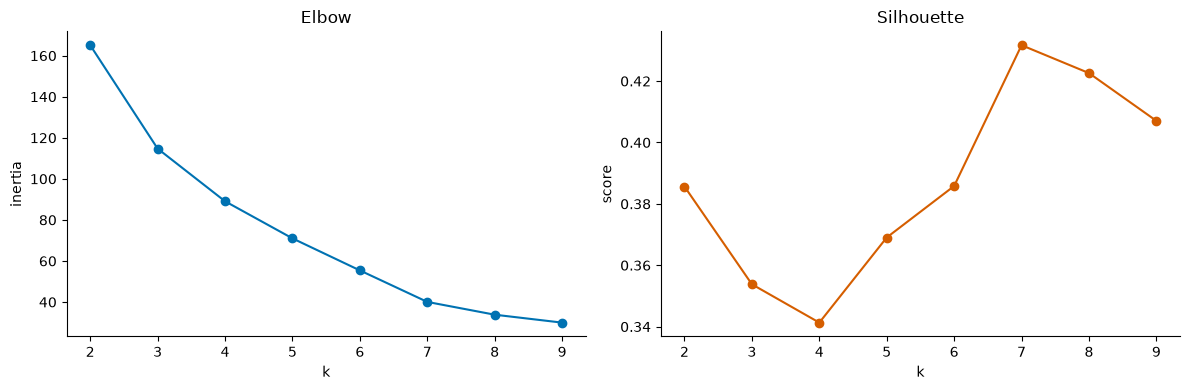

 k inertia silhouette
 2   165.1      0.386
 3   114.7      0.354
 4    89.1      0.341
 5    71.0      0.369
 6    55.4      0.386
 7    40.1      0.432
 8    33.8      0.423
 9    30.0      0.407


In [4]:
ks = range(2, 10)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(list(ks), inertia, "o-", color="#0072B2"); ax1.set_title("Elbow"); ax1.set_xlabel("k"); ax1.set_ylabel("inertia")
ax2.plot(list(ks), silhouette, "o-", color="#D55E00"); ax2.set_title("Silhouette"); ax2.set_xlabel("k"); ax2.set_ylabel("score")
for a in (ax1, ax2): a.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

scan = pd.DataFrame({"k": list(ks),
                     "inertia": [f"{v:,.1f}" for v in inertia],
                     "silhouette": [f"{v:.3f}" for v in silhouette]})
print(scan.to_string(index=False))

**k = 4 is used below**, and the reason is worth stating honestly rather than hiding.

The silhouette scores are modest at every k (the table above), because price and selling rate
form one continuous cloud rather than well-separated islands. No k is clearly "right" by the
numbers, and k = 4 in fact scores lowest in the scan. It is chosen because it cuts that cloud into groups a shop acts on differently -
the big-ticket machines, the everyday parts that turn over fast, and two slow-moving groups at
different prices - where k = 2 is little more than a price filter.

Choosing k on interpretability rather than on the silhouette alone is normal practice for
segmentation, but it is a judgement call and should be presented as one.

In [5]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
products["cluster"] = kmeans.labels_

profile = products.groupby("cluster").agg(
    products     = ("revenue", "size"),
    med_price    = ("avg_price", "median"),
    med_units_wk = ("units_per_wk", "median"),
    current      = ("status", lambda s: (s == "Current range").sum()),
    revenue      = ("revenue", "sum"),
)
profile["rev_share%"] = profile.revenue / products.revenue.sum() * 100
display(profile)

,products,med_price,med_units_wk,current,revenue,rev_share%
cluster,,,,,,
0,36,122.0,0.9,17,"587,988.0",1.9
1,43,623.3,0.5,25,"1,487,135.0",4.7
2,41,"4,070.8",0.9,21,"29,333,591.0",93.2
3,23,85.5,0.3,17,"50,077.0",0.2


### Naming the segments

Cluster numbers from K-Means are arbitrary and change if the data or seed changes, so the
names below are derived from each cluster's own statistics rather than written against a
cluster index by hand: the most expensive cluster is *Big-ticket*; of the rest, the fastest
seller is *Everyday, fast-moving*; of the two left, the dearer is *Mid-price, slow-moving* and
the other *Low-price, slow-moving*.

In [6]:
def name_segments(profile):
    names = {}
    big = profile.med_price.idxmax()
    names[big] = "Big-ticket"
    rest = profile.drop(index=big)
    fast = rest.med_units_wk.idxmax()
    names[fast] = "Everyday, fast-moving"
    rest = rest.drop(index=fast)
    names[rest.med_price.idxmax()] = "Mid-price, slow-moving"
    names[rest.med_price.idxmin()] = "Low-price, slow-moving"
    assert len(names) == len(profile)
    return names

segment_name = name_segments(profile)
products["segment"] = products.cluster.map(segment_name)

summary = (products.groupby("segment")
           .agg(products=("revenue", "size"), revenue=("revenue", "sum"),
                med_price=("avg_price", "median"), med_units_wk=("units_per_wk", "median"),
                current=("status", lambda s: (s == "Current range").sum()))
           .sort_values("revenue", ascending=False))
summary["rev_share%"] = summary.revenue / products.revenue.sum() * 100
display(summary)

for seg in summary.index:
    top = products[products.segment == seg].nlargest(3, "revenue")
    print(f"\n{seg}")
    for _, r in top.iterrows():
        print(f"   {r['name'][:46]:46} {r.category:16} RM {r.revenue:>11,.0f}")

,products,revenue,med_price,med_units_wk,current,rev_share%
segment,,,,,,
Big-ticket,41,"29,333,591.0","4,070.8",0.9,21,93.2
"Mid-price, slow-moving",43,"1,487,135.0",623.3,0.5,25,4.7
"Everyday, fast-moving",36,"587,988.0",122.0,0.9,17,1.9
"Low-price, slow-moving",23,"50,077.0",85.5,0.3,17,0.2



Big-ticket
   AMD Ryzen 9 5950X RTX 3090 Creator Workstation Complete PC Rig  RM   5,349,424
   AMD Ryzen 7 5800X3D RTX 3080 Gaming PC Rig     Complete PC Rig  RM   3,814,035
   AMD Ryzen 5 5600 RTX 3060 Gaming PC Rig        Complete PC Rig  RM   2,707,355

Mid-price, slow-moving
   Acer Nitro VG271U 27-inch QHD 170Hz Monitor    PC Peripherals   RM     116,415
   Epson EcoTank L5290 Multifunction Printer      Printer          RM     113,791
   Epson EcoTank L3250 Ink Tank Printer           Printer          RM     111,240

Everyday, fast-moving
   Kingston NV2 1TB NVMe SSD                      PC Components    RM      75,143
   Cooler Master MWE Bronze V2 650W PSU           PC Components    RM      69,983
   Seagate BarraCuda 2TB 7200RPM HDD              PC Components    RM      68,532

Low-price, slow-moving
   TP-Link Archer T3U Plus Wi-Fi Adapter          IT Accessories   RM       6,612
   UGREEN Adjustable Aluminium Laptop Stand       IT Accessories   RM       5,876
   UGREEN 4-Por

In [7]:
# What each segment is made of, by the shop's own categories
pd.crosstab(products.segment, products.category)

category,Cable,Complete PC Rig,IT Accessories,Laptop,PC Components,PC Peripherals,Printer
segment,,,,,,,
Big-ticket,0,14,0,15,10,0,2
"Everyday, fast-moving",16,0,1,0,12,6,1
"Low-price, slow-moving",1,0,15,0,1,2,4
"Mid-price, slow-moving",0,1,5,0,18,11,8


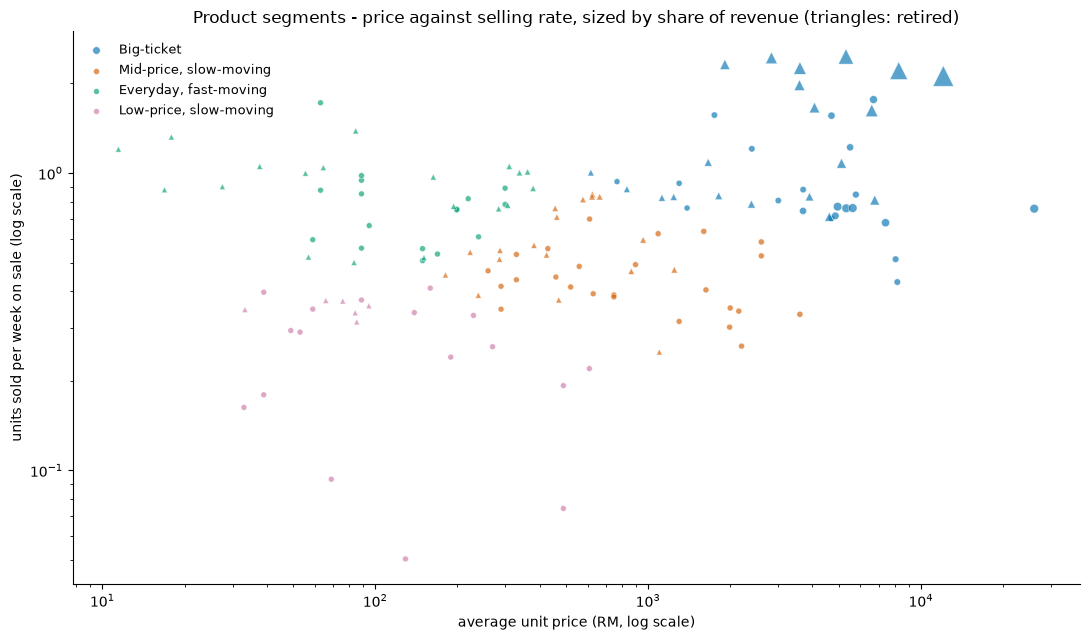

In [8]:
fig, ax = plt.subplots(figsize=(11, 6.5))
palette = ["#0072B2", "#D55E00", "#009E73", "#CC79A7"]
for i, seg in enumerate(summary.index):
    for status, marker in [("Current range", "o"), ("Retired", "^")]:
        s = products[(products.segment == seg) & (products.status == status)]
        ax.scatter(s.avg_price, s.units_per_wk, s=18 + s["rev_share%"] * 12, alpha=0.65, marker=marker,
                   color=palette[i], edgecolor="white", linewidth=0.5,
                   label=f"{seg}" if status == "Current range" else None)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("average unit price (RM, log scale)")
ax.set_ylabel("units sold per week on sale (log scale)")
ax.set_title("Product segments - price against selling rate, sized by share of revenue (triangles: retired)")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()

## ABC analysis, as a cross-check

Clustering groups products by *behaviour*. ABC ranks them by *contribution*, which is the
view a buyer is used to. The two answer different questions and are worth reading together.

In [9]:
abc = products.sort_values("revenue", ascending=False).copy()
abc["cum%"] = abc.revenue.cumsum() / abc.revenue.sum() * 100
abc["ABC"] = np.where(abc["cum%"] <= 80, "A", np.where(abc["cum%"] <= 95, "B", "C"))

display(abc.groupby("ABC").agg(products=("revenue", "size"), revenue=("revenue", "sum"),
                               med_price=("avg_price", "median")).assign(
        **{"products%": lambda d: d.products / len(abc) * 100,
           "rev%": lambda d: d.revenue / abc.revenue.sum() * 100}))

print("\nsegment against ABC class (product counts):")
display(pd.crosstab(products.segment, abc.ABC.reindex(products.index)))

,products,revenue,med_price,products%,rev%
ABC,,,,,
A,17,"24,811,335.0","5,113.0",11.9,78.9
B,26,"5,000,985.0","2,102.8",18.2,15.9
C,100,"1,646,471.0",249.0,69.9,5.2



segment against ABC class (product counts):


ABC,A,B,C
segment,,,
Big-ticket,17,20,4
"Everyday, fast-moving",0,0,36
"Low-price, slow-moving",0,0,23
"Mid-price, slow-moving",0,6,37


## The current range

The segments above mix the retired range with the current one. For restocking decisions only
the current range matters, so the same segments are shown for it alone, with the slowest
sellers listed: the products in the current range that turn over least often.

In [10]:
current = products[products.status == "Current range"]
display(current.groupby("segment").agg(products=("revenue", "size"), revenue=("revenue", "sum"),
                                       med_units_wk=("units_per_wk", "median"))
               .sort_values("revenue", ascending=False))

slowest = current.nsmallest(10, "units_per_wk")[["name", "category", "segment", "units", "weeks_on_sale", "units_per_wk"]]
slowest

,products,revenue,med_units_wk
segment,,,
Big-ticket,21,"5,023,103.0",0.8
"Mid-price, slow-moving",25,"365,164.0",0.4
"Everyday, fast-moving",17,"52,095.0",0.8
"Low-price, slow-moving",17,"19,658.0",0.3


,name,category,segment,units,weeks_on_sale,units_per_wk
sku,,,,,,
EITM-014,NZXT Internal USB Hub - 4 ports,IT Accessories,"Low-price, slow-moving",1,19.9,0.1
EITM-004,TP-Link Deco X10 (2-unit pack),IT Accessories,"Low-price, slow-moving",1,13.4,0.1
EITM-010,Deepcool RGB 200 Pro,IT Accessories,"Low-price, slow-moving",1,10.7,0.1
EITM-006,Slev ASQ Vortex Forward ARGB 120mm (White),IT Accessories,"Low-price, slow-moving",2,12.3,0.2
EITM-009,Tecware Orbis LED Strip,IT Accessories,"Low-price, slow-moving",6,33.4,0.2
EPRN-007,Canon G2010,Printer,"Low-price, slow-moving",6,31.1,0.2
EPRN-008,Epson EcoTank L3350,Printer,"Low-price, slow-moving",6,27.3,0.2
EITM-011,Slev ARGB Flexible Light Board V2 Kit,IT Accessories,"Low-price, slow-moving",8,33.3,0.2
EPRN-002,Canon E470,Printer,"Low-price, slow-moving",8,30.7,0.3


## Saving the assignments

In [11]:
out = products.reset_index()[["sku", "name", "category", "segment", "cluster", "status", "revenue", "units",
                              "receipts", "avg_price", "weeks_on_sale", "units_per_wk", "recency_wk", "rev_share%"]]
out = out.merge(abc.reset_index()[["sku", "ABC", "cum%"]], on="sku", how="left")
out.to_csv("data/processed/product_segments.csv", index=False)
print(f"wrote data/processed/product_segments.csv  ({len(out)} products)")
display(out.head(8))

wrote data/processed/product_segments.csv  (143 products)


,sku,name,category,segment,cluster,status,revenue,units,receipts,avg_price,weeks_on_sale,units_per_wk,recency_wk,rev_share%,ABC,cum%
0,CBL-001,UGREEN HDMI 2.0 Cable 2m,Cable,"Everyday, fast-moving",0,Retired,"7,720.0",206,33,37.7,195.7,1.1,40.6,0.0,C,99.5
1,CBL-002,Vention HDMI 2.1 Cable 2m,Cable,"Everyday, fast-moving",0,Retired,"23,780.0",282,54,84.7,203.6,1.4,36.7,0.1,C,98.5
2,CBL-003,UGREEN DisplayPort 1.4 Cable 2m,Cable,"Everyday, fast-moving",0,Retired,"9,508.0",171,31,55.5,171.3,1.0,68.7,0.0,C,99.3
3,CBL-004,Baseus USB-C 100W Data Cable 1m,Cable,"Everyday, fast-moving",0,Retired,"5,063.0",185,33,27.5,205.7,0.9,35.7,0.0,C,99.7
4,CBL-005,UGREEN USB-C to HDMI Cable,Cable,"Everyday, fast-moving",0,Retired,"13,150.0",204,38,64.5,195.7,1.0,45.6,0.0,C,99.3
5,CBL-006,TP-Link Cat6 Network Cable 3m,Cable,"Everyday, fast-moving",0,Retired,"4,832.0",271,54,17.9,205.1,1.3,35.3,0.0,C,99.8
6,CBL-007,UGREEN SATA III Data Cable,Cable,"Everyday, fast-moving",0,Retired,"2,691.0",236,43,11.4,196.3,1.2,37.7,0.0,C,99.9
7,CBL-008,Volex IEC C13 PC Power Cable,Cable,"Everyday, fast-moving",0,Retired,"3,091.0",183,33,16.9,208.4,0.9,34.9,0.0,C,99.8


## What this run says

1. **The products split four ways**, and the split follows how a shop works: a small group of
   big-ticket machines (complete rigs and laptops, with the most expensive components), the
   everyday parts that turn over fastest (storage, memory, power supplies, cables), and two
   slow-moving groups, one mid-priced (monitors, printers, motherboards) and one cheap
   (accessories).
2. **Revenue is concentrated in the big-ticket segment.** It carries the large majority of
   revenue on a minority of products (tables above), which is where a forecasting error costs
   most and where stock-outs matter most.
3. **The range change is visible, and kept out of the clustering.** Retired and current products
   separate cleanly by their last sale, and each segment holds both. Measuring selling rate
   rather than totals is what lets a four-year product and an eight-month one sit in the same
   segment.
4. **Segmentation here is about products, not people.** Worth stating explicitly in the
   report, with the reason: the receipts have no customer identifier.

### Next

- A per-segment forecast is the natural join between this notebook and `02_forecasting.ipynb`:
  the big-ticket segment and the everyday parts are clearly not moving at the same rate.
- The slowest-seller list depends on `as_of`. Rerun it as new months of receipts arrive.